# Искусственный интеллект — занятие 6
### Оптимизаторы в PyTorch и основы обработки текста

**Логика занятия:** как torch сам считает производные (`requires_grad`, `backward`) → зачем нужны оптимизаторы вместо ручного градиентного спуска и чем отличаются SGD, RMSprop, Adam, AdamW и Muon → затем переходим к тексту: графематический анализ, частоты слов, n-граммы, мешок слов и TF-IDF.

## 1. Тензоры torch и автодифференцирование

Импортируем `torch`, `numpy`, `re` и `matplotlib` — на них построено всё занятие.

Главное отличие тензоров torch от массивов NumPy — флаг `requires_grad`: такой тензор хранит две части, `data` (значение) и `grad` (производная). Как только в выражении появляется хотя бы один тензор с `requires_grad=True`, torch не считает функцию сразу, а строит **граф вычислений**, чтобы уметь получить её значение и производные в любой момент. Вызов `backward()` проходит по этому графу, считает частные производные по всем таким тензорам и записывает их в `grad`. Тензоры без этого флага — просто числа, производные по ним не считаются.

Важно: autograd **накапливает** градиенты (прибавляет к уже записанным, так быстрее), поэтому после каждого шага обучения их обнуляют — иначе они будут расти и обучение сломается.

### Градиентный спуск вручную

Ячейка ниже повторяет алгоритм, который раньше делали «на бумаге»: ищем минимум функции

$$f(x, y) = (x-5)^2 + (y-7)^2$$

из точки $(10, 10)$ с фиксированной скоростью обучения $\alpha = 0.1$. Шаг градиентного спуска — $w \leftarrow w - \alpha \cdot \nabla f(w)$; `w` здесь вектор-столбец из двух чисел, поэтому обновляются сразу обе координаты. После шага `w.grad.zero_()` обнуляет градиенты, а цикл останавливается, когда обе координаты подошли к $(5, 7)$ ближе чем на $10^{-4}$; на выходе печатаются найденная точка и номер шага.

Вся сложность тут — подбор $\alpha$: слишком большая даёт прыжки через минимум и расходимость, слишком маленькая — почти стояние на месте.

In [27]:
import torch
import numpy as np
import re
import numpy as np
import matplotlib.pyplot as plt

In [28]:

w=torch.tensor([[10.0],[10.0]],requires_grad=True)
alpha=0.1
for step in range(1000):
    function = (w[0]-5)**2+(w[1]-7)**2
    function.backward()
    w.data=w.data-alpha*w.grad
    w.grad.zero_()
    if abs(w.data[0]-5)<1e-4 and abs(w.data[1]-7)<1e-4:
        break
print(w,step)

tensor([[5.0001],
        [7.0001]], requires_grad=True) 48


## 2. Оптимизаторы PyTorch

Чтобы не подбирать шаг вручную, придумали **оптимизаторы**. Идею использовать для этого стохастический градиентный спуск предложил Илья Суцкевер — аспирант Джеффри Хинтона.

Функция потерь считается по всей выборке: $L = \sum_i (y_i - \hat y_i)^2$, а на миллионах объектов это слишком дорого. Поэтому градиент считают по случайному небольшому окну — **батчу** (например, 32 примера): много маленьких шажков надёжнее одного большого и неточного. Это и есть **SGD**. Но и ему шаг приходится подбирать: поверхность потерь — узкие глубокие «овраги», спуск строго по градиенту перепрыгивает минимум и мотается из стороны в сторону.

### Механизмы

- **Momentum (SGDM)** — усредняет направления предыдущих шагов: $v_t = \gamma v_{t-1} + \nabla f(w_t)$, $w_{t+1} = w_t - \alpha v_t$. «Прыжки» взаимно гасятся, движение к минимуму накапливается.
- **Nesterov** — градиент берётся не в текущей точке, а в точке «забегания вперёд» (предыдущий шаг продлевается на такое же расстояние). Сходится лучше momentum.
- **Adagrad** — сам решает, какого размера шаг делать: $\alpha_{eff} = \alpha / \sqrt{\sum g_i^2 + \varepsilon}$. Большие градиенты автоматически уменьшают шаг.
- **RMSprop** — то же, но усреднение не по всем прошлым шагам, а скользящее: $s_t = \gamma s_{t-1} + (1-\gamma) g_t^2$. При $\gamma \approx 0.1$ усредняются примерно 10 последних шагов, поэтому оценка подстраивается под текущий участок функции.
- **Adadelta** — более аккуратный расчёт эффективной скорости обучения; на практике используется редко.
- **Adam** — объединяет RMSprop (шаг) и momentum (направление): $w \leftarrow w - \alpha \, \dfrac{m_t}{\sqrt{s_t} + \varepsilon}$, где $\gamma_1$ отвечает за усреднение направления, $\gamma_2$ — за усреднение шага.
- **AdamW** — Adam плюс борьба за маленькие коэффициенты (**weight decay**). Пример с термометрами: модели $T_1$, $T_1 + T_2$ и $1000T_1 - 999T_2$ на точных данных дают одно и то же, но ошибка $0.01$ в показании $T_1$ превращается у третьей модели в десятки градусов, а у скромных — в сотые доли. Минимумов одинаковой глубины в пространстве много, и AdamW чуть подтягивает траекторию к нулю: путь длиннее, зато коэффициенты минимальны и модель устойчива к шумам.
- **Muon** — учитывает, что градиенты по разным коэффициентам не независимы: матрицу весов раскладывают (ортогонализация, по сути метод главных компонент) и делают шаг вдоль главных направлений. Нужен GPU — разложения матриц вычислительно дороги. Именно этим оптимизатором обучают современные языковые модели (Kimi, GLM).

### Сводная таблица

| Оптимизатор | Что адаптирует |
|---|---|
| `SGD` | ничего — шаг и направление фиксированы |
| momentum, Nesterov | направление |
| Adagrad, RMSprop, Adadelta | длину шага |
| Adam | и шаг, и направление |
| AdamW | то же + величину весов (weight decay) |
| Muon | направление (через разложение матрицы весов) |

### Шаг оптимизатора вместо ручного обновления

В ячейке ниже от ручного спуска остались три замены: оптимизатор создаётся сразу с параметрами и скоростью обучения (`torch.optim.SGD([w], lr=alpha)`), вместо `w.data = w.data - alpha*w.grad` вызывается `optimizer.step()`, а вместо `w.grad.zero_()` — `optimizer.zero_grad()`: оптимизатор сам знает, какие градиенты обнулять, потому что параметры ему передали при создании. На этом примере SGD с $\alpha = 0.1$ доходит до минимума за 48 шагов.

Параметры, которые оптимизатору не передали, он не обновляет. Значит, разным слоям можно назначить разные оптимизаторы — лектору это однажды понадобилось, чтобы модель вообще начала учиться за разумное время.

In [29]:

w=torch.tensor([[10.0],[10.0]],requires_grad=True)
alpha=0.1
optimizer = torch.optim.SGD([w], lr=alpha)
for step in range(1000):
    function = (w[0]-5)**2+(w[1]-7)**2
    function.backward()
    optimizer.step()
    optimizer.zero_grad()
    if abs(w.data[0]-5)<1e-4 and abs(w.data[1]-7)<1e-4:
        break
print(w,step)

tensor([[5.0001],
        [7.0001]], requires_grad=True) 48


## 3. Сравнение оптимизаторов

Задание с занятия: прогнать одну и ту же задачу через разные оптимизаторы и свести в таблицу, сколько шагов каждому потребовалось, чтобы добраться до минимума. Список для сравнения — `SGD`, `RMSprop`, `Adam`, `AdamW` и `Muon`; всего в `torch.optim` около 17 оптимизаторов, полный набор виден в документации.

В коде имена перебираются в цикле, а класс оптимизатора достаётся из модуля по имени: `getattr(torch.optim, f[i])([w], lr=alpha)`. Для каждого оптимизатора точка старта $(10, 10)$ создаётся заново, $\alpha = 0.1$, выход из цикла — когда обе координаты ближе $10^{-4}$ к $(5, 7)$; печатаются название, найденная точка и число шагов.

Вывод: у `SGD` фиксированы и шаг, и направление, у остальных меняется либо шаг, либо направление, либо и то и другое. Универсального победителя нет — результат зависит от архитектуры сети и датасета, и иногда достаточно сменить оптимизатор, чтобы обучение пошло лучше. Лектор обычно выбирает между `SGD`, `RMSprop` и `Adam`.

Домашнее задание: заполненную таблицу «оптимизатор → число шагов» скинуть в чат.

In [30]:
import torch

f = ['RMSprop', 'Adam', 'AdamW', 'SGD']

for i in range(len(f)):
    w = torch.tensor([[10.0], [10.0]], requires_grad=True)
    alpha = 0.1
    optimizer = getattr(torch.optim, f[i])([w], lr=alpha)
    
    for step in range(1000):
        function = ((w[0]-5)**2 + (w[1]-7)**2).sum()
        function.backward()
        optimizer.step()
        optimizer.zero_grad()
        if abs(w.data[0]-5) < 1e-4 and abs(w.data[1]-7) < 1e-4:
            break
            
    print(f[i], w.data.tolist(), step)


RMSprop [[5.000091075897217], [7.000000476837158]] 77
Adam [[4.9999518394470215], [6.999905586242676]] 196
AdamW [[4.975133895874023], [6.983707427978516]] 999
SGD [[5.000089168548584], [7.000053405761719]] 48


## 4. Компьютерная лингвистика и уровни анализа текста

От чисел переходим к тексту: компьютерная лингвистика занимается пониманием естественного языка машинами и предсказанием по тексту. Языки бывают **формальные** — правила заданы чётко, любое отклонение считается ошибкой (математика, программирование), — и **естественные**, где правила размыты и меняются во времени и по регионам.

В языке два вида правил: правила построения цепочек (из слов складываются корректные предложения) и правила соответствия объектов реального мира. В формальном языке должны работать оба сразу; в естественном предложение может удовлетворять только первому — и всё равно часть информации передаёт. Классический пример — «Варкалось. Хливкие шорьки пырялись по наве...»: таких слов в реальности нет, но мы всё равно поняли, что что-то происходило и кто-то что-то делал. Так же и большие языковые модели: ответ может быть гладким по форме, но бессмысленным по фактам.

Уровни анализа текста:

- **графематический** — разбиение текста на предложения и слова; по тексту строится граф: том → глава → абзац → предложение → слово → буква;
- **морфологический** — определение основы слова: у существительного это именительный падеж единственного числа, у глагола — неопределённая форма; отсюда же **лемматизация**: «столы» → «стол», «Васи» → «Вася», «ножницы» → «ножницы»;
- **синтаксический** — «кто на ком стоял»: одно и то же слово может быть и существительным, и глаголом («Мама мыла раму»), порядок слов несёт дополнительный смысл, а членов предложения в разных языках находят десятки;
- **семантический** — понимание смысла, включая **коллокации**: «крепкий чай», «дать дуба» — сочетания, у которых своё значение, не сводимое к отдельным словам.

**Токен** — базовая неделимая единица, с которой работает модель, а **токенизация** — перевод текста в токены. Токены выбираем мы сами: буквы, слова, предложения, главы — на каком уровне остановиться, зависит от задачи.

Говорили и о проверке «понимания». Тест Тьюринга прошла ещё программа-«психотерапевт» (ЭЛИЗА): искусственного интеллекта в ней не было, она просто реагировала на знакомые слова и задавала наводящие вопросы. Оценивать тест Тьюринга неудобно — непонятно, где правильный ответ и по каким критериям судить. Поэтому используют схему Винограда: в одном предложении два похожих существительных, во втором — местоимение, и надо понять, к какому из них оно относится; смысл меняется одним словом. Отвечать на такое без фактов о мире нельзя (пример: население России ~150 млн, а Москвы ~15 млн — заменив число, получаем другую отсылку местоимения). Модели поколения до ChatGPT решали около 86% таких задач.

## 5. Графематический анализ: предложения и их длины

Практика начинается с настоящего текста: на Project Gutenberg скачан «Моби Дик» (лектор: название так себе, зато текст очень хороший), в ноутбуке это файл `files/15-0.txt` — порядка 10 тысяч предложений.

Программа устроена в три шага: читаем текст, режем его на предложения по знакам `.`, `?`, `!` (регулярка `[\?!\.]+\s+`), а внутри каждого предложения считаем слова — разделителем считается всё, что не является буквой или подчёркиванием (`\W+`). Полученные длины в словах складываются в массив и рисуются гистограммой на 100 карманов.

Почему именно 100 бинов? Предложений около 10 тысяч: сотни карманов хватает, чтобы увидеть форму распределения, и при этом отдельные редкие значения картину не портят. `print(len(w))` печатает число предложений в тексте — его удобно сверить с ожидаемым.

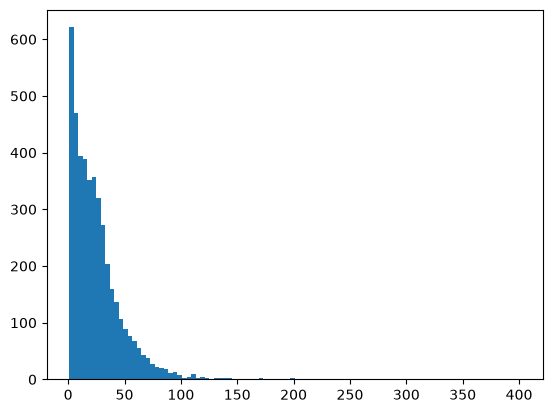

4319


In [32]:

f = open('files/15-0.txt')
s = f.read()
w = re.split(r'[\?!\.]+\s+', s)
d = []
for s in w:
    k = re.split(r'\W+', s)
    d.append(len(k))
d = np.array(d)
plt.hist(d, bins=100)
plt.show()
print(len(w))
#print(len(set(w)))


## 6. Частоты слов и закон Ципфа

Следующий шаг — статистика слов: сколько раз каждое слово встретилось в тексте. Считаем её в словаре: ключ — слово, значение — счётчик (ключами словаря могут быть только неизменяемые, хешируемые объекты, поэтому слова приводят к нижнему регистру). Потом словарь сортируется по второму элементу — частоте — по убыванию, и рисуется график: по оси X ранг слова, по оси Y частота, шкала по вертикали логарифмическая.

Такое распределение описывается **законом Ципфа**:

$$f(r) \sim \frac{1}{r^c},$$

где $r$ — ранг слова, $c$ — показатель. Смысл: в тексте есть несколько очень частых слов и очень много очень редких. Наверху почти всегда оказываются служебные слова — союзы и предлоги (в английском ещё артикли `the`/`a`), поэтому «сырая» частота слова ничего не говорит о его значимости.

Статистика по «сырым» словам вообще неточная: в русском мешают окончания, единственное и множественное число. Именно поэтому дальше нужна лемматизация — приведение слова к нормальной форме.

Домашнее задание: построить такой же график для «Войны и мира» Л. Н. Толстого — форма распределения сохранится, поменяются только сами слова.

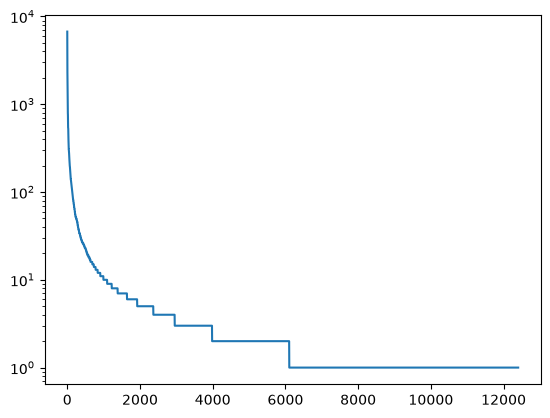

In [44]:
import re
import matplotlib.pyplot as plt

f = open('files/15-0.txt', 'r', encoding='utf-8')
s = f.read()
w = re.split(r'[\?!\.]+\s+', s)

word_counts = {}

for sentence in w:
    k = [word.lower() for word in re.split(r'\W+', sentence) if word]
    for word in k:
        if word in word_counts:
            word_counts[word] += 1
        else:
            word_counts[word] = 1

# Сортируем и берем топ-20 самых частых слов
words = sorted(word_counts.items(), key=lambda item: item[1], reverse=True)

d=[]
for k,v in words:
  d.append(v)
plt.yscale('log')
plt.plot(d)

## 7. N-граммы

Слов в языке очень много, и словоизменение мешает: приставка, суффикс, окончание меняют форму слова. Нужен метод, который отделял бы значимые части слова (корень) от служебных. Простейший подход — резать текст на куски длиной N символов, то есть на **n-граммы**: биграммы — по 2 символа, триграммы — по 3 и так далее.

Для «Мама мыла раму» биграммы такие: «Ма», «ам», «ма», ..., «мы», «ыл», «ла», ..., «ра», «ам», «му» (куски, попавшие на пробел, тоже выведутся). Редкие кусочки — «квази-слоги» — повторяются в однокоренных словах, и по ним можно собирать морфологию. N-граммы бывают не только из букв, но и из слов — тогда это короткие словосочетания. Частоты n-грамм в тексте, как и частоты слов, — это text frequency (TF).

Функция `splitN(w, N=2)` ниже превращает строку в список символов и печатает все подряд идущие куски длины N. Задание с занятия — разбить на биграммы «Мама мыла раму». Обратите внимание: в конце ячейки стоит `quit()` — она завершает работу ядра, поэтому запускать эту ячейку стоит последней.

In [46]:
import re
def splitN(w, N=2):
    t = list(w)
    for s in range(len(t) - N):
        print(''.join(t[s:s + N]))

splitN('Мама мыла раму', 2)
quit()

Ма
ам
ма
а 
 м
мы
ыл
ла
а 
 р
ра
ам


## 8. Векторизация текста: мешок слов и TF-IDF

Модели не понимают буквы: слова для них — категориальные символы, между которыми нет никаких отношений. Поэтому каждый токен кодируют набором чисел — вектором (**эмбеддингом**), а весь текст превращается в матрицу: строки — документы, столбцы — элементы словаря.

О выборе токенов: буквы берут редко — их слишком мало (латиница, кириллица, цифры и знаки — около 100 символов), предложения — тоже плохая идея, разных вариантов слишком много; обычно работают со словами или частями слов.

Базовый способ кодировки — **мешок слов** (bag of words): порядок слов не важен, важно только, сколько раз каждое слово встретилось. Вектор документа можно делать **двоичным** (слово встретилось — 1, нет — 0; такие кодировки часто нужны при разметке текста), **счётчиками** или **частотами**: нормировка по норме L1 (делим на сумму — получаем вероятность) или по норме L2 (делим на корень из суммы квадратов).

Чтобы выделить значимые слова, вводят две величины: **TF** (term frequency) — сколько раз слово встречается в документе, и **DF** (document frequency) — в скольких документах корпуса оно встречается вообще. Служебное слово есть почти во всех документах и потому «ничего не значит»; самые редкие слова (вплоть до опечаток, которые уникальны) слишком специфичны. Ключевые слова — посередине: часто в этом документе, редко в остальных.

Мера этого компромисса — **TF-IDF**:

$$w_{t,d} = tf_{t,d} \cdot \log\frac{N}{df_t},$$

где $N$ — число документов корпуса. Если слово есть во всех документах, $df = N$, $\log 1 = 0$ и вес обнуляется; если в одном — вес максимальный. Иногда в знаменатель добавляют единицу, чтобы не делить на ноль.

### Датасет 20 newsgroups

Работаем с датасетом **20 newsgroups** — архив новостных групп: сообщения рассылали по обычным телефонным линиям ещё до мобильных телефонов (прародитель — сеть FidoNet). В нём 20 тем, каждое сообщение помечено классом: `data` — тексты, `target` — номера классов, `target_names` — названия тем. Типовая задача — по тексту сообщения определить его тему.

`TfidfVectorizer` собирает словарь по всему корпусу и превращает каждый документ в вектор TF-IDF-весов — на выходе матрица «документы × слова» (здесь примерно 11 тысяч документов и 130 тысяч столбцов-слов). Вектор весов одного документа и есть его «портрет» — гистограмма мешка слов.

Домашнее задание: построить два таких «портрета» для первого и второго документа и убедиться, что они отличаются.

In [ ]:
from sklearn.datasets import fetch_20newsgroups
train = fetch_20newsgroups(subset='train')
print(train.data)
print(train.target)
print(train.target_names)

from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform(train.data)
print(vectors.shape)
print(vectors[:1])
d[]

plt.yscale('log')
plt.plot(vectors)

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



(11314, 130107)
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 89 stored elements and shape (1, 130107)>
  Coords	Values
  (0, 56979)	0.0574701540748513
  (0, 75358)	0.3538350134970617
  (0, 123162)	0.25970902457356887
  (0, 118280)	0.21186807208281694
  (0, 50527)	0.05461428658858725
  (0, 124031)	0.10798795154169123
  (0, 85354)	0.03696978508816317
  (0, 114688)	0.06214070986309587
  (0, 111322)	0.019156718024950434
  (0, 123984)	0.036854292634593756
  (0, 37780)	0.3813389125949312
  (0, 68532)	0.07325812342131598
  (0, 114731)	0.1444727551278406
  (0, 87620)	0.0356718631408158
  (0, 95162)	0.03447138409326312
  (0, 64095)	0.035420924271313554
  (0, 98949)	0.16068606055394935
  (0, 90379)	0.01992885995664587
  (0, 118983)	0.03708597805061915
  (0, 89362)	0.06521174306303765
  (0, 79666)	0.10936401252414275
  (0, 40998)	0.07801368196918111
  (0, 92081)	0.09913274493911224
  (0, 76032)	0.01921946305222309
  (0, 4605)	0.06332603952480324
  :	:
  (0, 37565)	0.0343176044247

## 9. Домашнее задание

- Таблица сравнения оптимизаторов (`SGD`, `RMSprop`, `Adam`, `AdamW`, `Muon`): сколько шагов каждому нужно, чтобы дойти до минимума. Код уже готов — меняется только имя оптимизатора в списке; результат скинуть в чат.
- «Моби Дик» с Project Gutenberg: программа (буквально в 5 строк), которая считает число предложений в тексте.
- Распределение длин предложений в словах для этого текста.
- Закон Ципфа для «Войны и мира» Л. Н. Толстого — форма распределения должна сохраниться.
- Два «портрета» TF-IDF (гистограммы весов) для первого и второго документа из 20 newsgroups — они должны отличаться.

Последняя кодовая ячейка ноутбука осталась пустой: на занятии до неё не дошли, это место для самостоятельных экспериментов.

---

**Итог занятия 6.** Разобрали автодифференцирование в PyTorch (`requires_grad`, граф вычислений, `backward`, накопление градиентов) и путь от ручного градиентного спуска к оптимизаторам: SGD и мини-батчи, momentum, Нестеров, Adagrad, RMSprop, Adadelta, Adam, AdamW и Muon — и сравнили, за сколько шагов они доходят до минимума. Во второй части перешли к тексту: формальные и естественные языки, уровни анализа (графематический, морфологический, синтаксический, семантический), токены, распределение длин предложений, частоты слов и закон Ципфа, n-граммы, мешок слов и TF-IDF на датасете 20 newsgroups.